# 01 · Dataset analysis and research design

**SCAR-MLKEM · ML-KEM-768 on Raspberry Pi 5**

The scientific question is whether causal reuse prediction can reduce complete secret-key reconstruction and decapsulation cost under explicit expanded-key memory and lifetime limits. Seed representation and expanded-key caching are established techniques, not new cryptographic constructions.

**Execution locations:** this notebook and all analysis run on the MacBook. Native operations were measured on the Raspberry Pi 5 over controlled workloads; SSH is the transport for running instruments and retrieving their logs. No laptop timing is attributed to the Pi.

An observation is one real decapsulation request. A fresh process/session with an independent public workload seed is the replication unit. A key ID is an anonymized, session-local context, never private key material. The prospective label is whether that context is requested again within a future horizon. This notebook performs no model fitting.

RQ1: what is the reconstruction cost? RQ2: are temporal reuse patterns present? RQ3: can a history-only predictor exploit them? RQ4: can a bounded controller produce net system benefit after its costs? Only the first two questions are explored here.

The controlled request schedules are generated workloads, **not production key-access traces**. IoT-23 contains network connections, not ML-KEM key requests. No external power meter is available; energy is unmeasured. Final test sessions are generated only after the complete method is frozen.

In [1]:
from pathlib import Path
import hashlib, json, re, platform
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
DATA = ROOT / "dataset"
RAW = DATA / "raw"
TABLES, FIGURES = ROOT / "artifacts", ROOT / "figures"
for p in (TABLES, FIGURES, DATA / "interim", DATA / "splits"):
    p.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 180)
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size":18,
    "axes.titlesize":20,"axes.labelsize":20,"xtick.labelsize":18,
    "ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,
    "savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#4D4D4D"]

def save_table(frame, name, *, show=True, exclude=(), columns=None):
    frame.to_csv(TABLES / f"01_{name}.csv", index=True)
    frame.to_latex(TABLES / f"01_{name}.tex", index=True, float_format="%.3f")
    if show:
        visible = frame.loc[:, columns] if columns is not None else frame.drop(columns=list(exclude))
        display(visible)
def save_figure(fig, name, source):
    # Compact physical canvas, unchanged 18/20 pt text. Wrap instead of shrinking.
    import textwrap
    for axis in fig.axes:
        if axis.get_title():
            axis.set_title(textwrap.fill(axis.get_title().replace("\n", " "), width=max(32, int(fig.get_figwidth()*5))))
        label=axis.get_xlabel()
        if label and len(label)>44:
            axis.set_xlabel(textwrap.fill(label.replace("\n", " "),width=44))
    fig.set_layout_engine("constrained")
    fig.savefig(FIGURES / f"01_{name}.png", dpi=350, bbox_inches="tight")
    fig.savefig(FIGURES / f"01_{name}.pdf", dpi=350, bbox_inches="tight")
    source.to_csv(TABLES / f"01_{name}_source.csv", index=False)
    plt.show()
    plt.close(fig)
design = json.loads((ROOT / "support/configs/development_design.json").read_text())
assert design["test_generation_gate"] == "pipeline_freeze_manifest_required"

## 01.2 · Provenance and local source integrity

External source hashes are checked against the acquisition manifest. Native experimental files are checked against the collection manifest. Hash verification establishes file identity, not the absence of all possible acquisition or implementation errors. The detailed scientific EDA below uses training sessions; development is checked only for integrity and declared coverage.

In [2]:
external = pd.read_csv(DATA / "provenance/acquisition_manifest.tsv", sep="\t")
assert len(external) == 55
for item in external.itertuples():
    p = DATA / relocate(item.path)
    if item.group == "IoT23" and not p.exists():
        continue  # the IoT-23 logs are not redistributed here; download them as described in dataset/README.md
    assert p.stat().st_size == item.bytes
    assert hashlib.sha256(p.read_bytes()).hexdigest() == item.sha256
D = RAW / "Development_v1"
verified = 0
for line in (D / "SHA256SUMS").read_text().splitlines():
    expected, rel = line.split(maxsplit=1)
    p = D / Path(rel).name
    assert hashlib.sha256(p.read_bytes()).hexdigest() == expected
    verified += 1
manifest = pd.read_csv(D / "session_manifest.csv")
assert manifest.session_id.is_unique
assert set(manifest.split) == {"train", "development"}
assert not any("test" in s for s in manifest.session_id)
all_events = pd.concat([pd.read_csv(D / f"{sid}.csv") for sid in manifest.session_id], ignore_index=True)
assert all_events.groupby("session_id").size().eq(1000).all()
assert set(all_events.session_id) == set(manifest.session_id)
assert all_events.groupby("session_id").split.nunique().eq(1).all()
frame = external.groupby("group").agg(Files=("path","size"), Bytes=("bytes","sum"))
frame["MiB"] = frame.Bytes / 2**20
frame["Role"] = ["Network context, not key access" if i=="IoT23" else "Public cryptographic test fixtures" for i in frame.index]
save_table(frame, "source_inventory")
coverage = manifest.groupby(["split","workload_id"]).agg(Sessions=("session_id","size"), Requests=("requests","sum"), Contexts=("key_contexts","first"))
save_table(coverage, "experimental_coverage")
df = all_events.loc[all_events.split.eq("train")].copy()

,Files,Bytes,MiB,Role
group,,,,
IoT23,19,30299452,28.895809,"Network context, not key access"
NIST_ACVP,18,6286975,5.995727,Public cryptographic test fixtures
Wycheproof,18,8430579,8.040027,Public cryptographic test fixtures


Sessions  Requests  Contexts
split       workload_id                                   
development abrupt                   3      3000        64
            bursty                   3      3000        64
            hotcold                  3      3000        64
            nonstationary            3      3000        64
            periodic                 3      3000        64
            poisson                  3      3000        64
            thrashing                3      3000        64
            uniform                  3      3000        64
            varying_contexts         3      3000       128
            zipf                     3      3000        64
train       abrupt                   6      6000        64
            bursty                   6      6000        64
            hotcold                  6      6000        64
            nonstationary            6      6000        64
            periodic                 6      6000        64
            poisson                  6      6000        64
            thrashing                6      6000        64
            uniform                  6      6000        64
            varying_contexts         6      6000       128
            zipf                     6      6000        64

**Interpretation.** All 55 acquired source files and 271 experimental files retain their recorded identity. The main dataset has 60 training and 30 development sessions with balanced designed-family coverage; this balance is experimental, not a claim about deployed IoT traffic.

## 01.3 · Observation schema and measurement semantics

Latency and CPU cycles are measured by the native process. CPU cycles exclude kernel/hypervisor time; counter reads and validation/erasure remain in full service time. Frequency and temperature are sampled every 64 requests and carried forward, not independently measured for every row. Peak RSS is a session-level process high-water mark repeated on its event rows. It includes the request fixture arena and is **not cache-only memory**.

The initial collector uses seed-only decapsulation: zero retained expanded-key bytes, one reconstruction per request. `policy_overhead_ns` here is residual instrumentation/validation/erasure cost; it is not a learned policy's cost. `key_residency_ms=0` denotes no retention between requests, not zero transient key lifetime. Arrival and response timestamps use the same monotonic clock. UTC anchors and counters are recorded in the sidecar metadata.

In [3]:
units = {c:"categorical / identifier" for c in all_events}
units.update({c:"ns" for c in all_events if c.endswith("_ns")})
units.update({c:"bytes" for c in all_events if c.endswith("_bytes")})
units.update({"interarrival_us":"µs","cpu_frequency_mhz":"MHz (sampled)","temperature_c":"°C (sampled)",
    "cpu_cycles":"user-mode cycles","max_residency_ms":"ms","key_residency_ms":"ms (retained state)",
    "measured_power_w":"W (unmeasured)","energy_per_operation_uj":"µJ (unmeasured)"})
for c in ["sequence_index","window_id","request_id","key_id","key_contexts","eviction_count"]: units[c]="count / index"
for c in ["operation_success","cache_hit","cache_miss"]: units[c]="binary"
schema = pd.DataFrame({"Type":all_events.dtypes.astype(str),"Unit":[units[c] for c in all_events],"Available":all_events.notna().sum()})
save_table(schema, "schema")
sessions = df.groupby(["workload_id","session_id"]).agg(n=("request_id","size"), start_ns=("timestamp_ns","min"), end_ns=("timestamp_ns","max"), contexts=("key_id","nunique"))
sessions["duration_s"]=(sessions.end_ns-sessions.start_ns)/1e9
sessions["observed_rate_per_s"]=(sessions.n-1)/sessions.duration_s
save_table(sessions.groupby("workload_id").agg(Sessions=("n","size"), Duration_s_median=("duration_s","median"), Rate_per_s_median=("observed_rate_per_s","median"), Observed_contexts_median=("contexts","median")), "temporal_coverage")

,Type,Unit,Available
run_id,str,categorical / identifier,90000
session_id,str,categorical / identifier,90000
request_id,int64,count / index,90000
key_id,int64,count / index,90000
workload_id,str,categorical / identifier,90000
split,str,categorical / identifier,90000
timestamp_ns,int64,ns,90000
scheduled_arrival_ns,int64,ns,90000
interarrival_us,float64,µs,90000
sequence_index,int64,count / index,90000


,Sessions,Duration_s_median,Rate_per_s_median,Observed_contexts_median
workload_id,,,,
abrupt,6,0.499496,2000.016148,55.0
bursty,6,0.482921,2068.659957,28.0
hotcold,6,0.499495,2000.018066,50.5
nonstationary,6,0.499495,2000.018567,64.0
periodic,6,0.499496,2000.016743,59.0
poisson,6,0.492090,2030.117816,64.0
thrashing,6,0.499497,2000.012709,17.0
uniform,6,0.499497,2000.013898,64.0
varying_contexts,6,0.499495,2000.018735,122.5


**Interpretation.** Most sessions cover approximately 0.5 s at 2,000 requests/s. The burst generator has clustered activity; only 17 of 64 possible contexts are used in the thrashing scenario. The varying-context family expands to 128 contexts. Short duration limits sustained-load and tail-latency claims.

## 01.4 · Quality, missingness and impossible values

Expected absence of energy is reported explicitly and is never replaced by zero. Repeated key IDs are meaningful requests; duplicate `(session_id, request_id)` records would be an acquisition defect. High delays are retained unless an identifiable instrument failure invalidates a complete session.

In [4]:
numeric = all_events.select_dtypes(include="number")
missing = pd.DataFrame({"Missing":numeric.isna().sum(),"Infinity":np.isinf(numeric).sum()})
missing["Interpretation"] = ["Unavailable: no power meter" if c in {"measured_power_w","energy_per_operation_uj"} else "Measured / recorded" for c in missing.index]
save_table(missing, "missingness")
monotonic_violations = sum((g.timestamp_ns.diff().dropna() <= 0).sum() for _,g in all_events.groupby("session_id",sort=False))
checks = pd.Series({"Duplicate event identifiers":all_events.duplicated(["session_id","request_id"]).sum(),
    "Exact duplicate rows":all_events.duplicated().sum(), "Non-increasing event times":monotonic_violations,
    "Unsuccessful cryptographic operations":all_events.operation_success.ne(1).sum(),
    "Nonpositive reconstruction durations":all_events.key_reconstruction_ns.le(0).sum(),
    "Nonpositive decapsulation durations":all_events.decapsulation_ns.le(0).sum(),
    "Response shorter than service":all_events.response_ns.lt(all_events.service_ns).sum(),
    "Negative measured overhead":all_events.policy_overhead_ns.lt(0).sum(),
    "Seed-only cache occupancy violations":all_events.cache_occupancy_bytes.ne(0).sum(),
    "Unexpected missing resource counter":all_events.cpu_cycles.isna().sum()})
save_table(checks.rename("Count").to_frame(), "quality_checks")
assert checks.eq(0).all(), "Repair an observed quality issue before proceeding"
assert set(numeric.columns[numeric.isna().any()]) == {"measured_power_w","energy_per_operation_uj"}
assert not np.isinf(numeric).any().any()
throttle = []
for sid in manifest.session_id:
    matches = re.findall(r"throttled=(0x[0-9a-fA-F]+)", (D/f"{sid}.environment").read_text())
    throttle.append({"session_id":sid,"states":matches,"nonzero":any(int(s,16) for s in matches)})
assert all(len(x["states"])==2 for x in throttle)

,Missing,Infinity,Interpretation
request_id,0,0,Measured / recorded
key_id,0,0,Measured / recorded
timestamp_ns,0,0,Measured / recorded
scheduled_arrival_ns,0,0,Measured / recorded
interarrival_us,0,0,Measured / recorded
sequence_index,0,0,Measured / recorded
window_id,0,0,Measured / recorded
key_contexts,0,0,Measured / recorded
cache_budget_bytes,0,0,Measured / recorded
max_residency_ms,0,0,Measured / recorded


,Count
Duplicate event identifiers,0
Exact duplicate rows,0
Non-increasing event times,0
Unsuccessful cryptographic operations,0
Nonpositive reconstruction durations,0
Nonpositive decapsulation durations,0
Response shorter than service,0
Negative measured overhead,0
Seed-only cache occupancy violations,0
Unexpected missing resource counter,0


**Interpretation.** Every measured operation succeeded, all event IDs are unique, and timestamps increase within each session. Both energy fields are wholly absent by design. No nonzero throttle flag was recorded; that does not rule out ordinary dynamic frequency scaling or prove zero thermal influence.

## 01.5 · Descriptive statistics

Event-level distributions describe within-session observations. They do not turn dependent event rows into independent replications. Duration, frequency and thermal comparisons may reflect governor and scheduling effects; causal effects require the later paired experiments.

In [5]:
measures = pd.DataFrame({"Reconstruction (µs)":df.key_reconstruction_ns/1000,
    "Decapsulation (µs)":df.decapsulation_ns/1000,"Service (µs)":df.service_ns/1000,
    "Response (µs)":df.response_ns/1000,"Interarrival (µs)":df.interarrival_us,
    "CPU cycles":df.cpu_cycles,"Temperature (°C)":df.temperature_c})
stats=measures.agg(["count","mean","median","std","min","max"]).T
stats["IQR"]=measures.quantile(.75)-measures.quantile(.25)
stats["p95"]=measures.quantile(.95);stats["p99"]=measures.quantile(.99)
stats["CV"]=stats["std"]/stats["mean"]
stats.loc["Temperature (°C)","CV"]=np.nan  # Celsius lacks a ratio-scale zero.
save_table(stats.round(3), "descriptive_statistics")
by_workload=df.groupby("workload_id").agg(Requests=("request_id","size"), Reconstruct_us=("key_reconstruction_ns",lambda x:x.median()/1000), Decaps_us=("decapsulation_ns",lambda x:x.median()/1000), Service_p95_us=("service_ns",lambda x:x.quantile(.95)/1000), Response_p99_us=("response_ns",lambda x:x.quantile(.99)/1000), Frequency_MHz=("cpu_frequency_mhz","median"), Temperature_C=("temperature_c","median"))
save_table(by_workload.round(3), "workload_latency")
frequency_strata=df.groupby("cpu_frequency_mhz").agg(Requests=("request_id","size"), Median_service_us=("service_ns",lambda x:x.median()/1000), Median_cycles=("cpu_cycles","median"))
save_table(frequency_strata, "frequency_strata")

,count,mean,median,std,min,max,IQR,p95,p99,CV
Reconstruction (µs),60000.0,21.358,20.130,3.148,19.963,61.909,0.093,30.167,30.481,0.147
Decapsulation (µs),60000.0,30.465,28.704,4.486,28.537,59.149,0.297,43.038,44.482,0.147
Service (µs),60000.0,52.906,49.871,7.772,49.500,92.261,0.370,74.742,77.650,0.147
Response (µs),60000.0,108.644,103.183,26.536,59.243,642.815,0.563,129.772,178.166,0.244
Interarrival (µs),60000.0,498.341,499.951,307.141,53.631,5097.775,0.444,586.885,2200.142,0.616
CPU cycles,60000.0,117912.314,117471.000,1420.248,116782.000,138844.000,394.000,122535.000,123181.000,0.012
Temperature (°C),60000.0,49.828,49.600,0.814,47.400,52.350,1.100,51.250,51.250,NaN


,Requests,Reconstruct_us,Decaps_us,Service_p95_us,Response_p99_us,Frequency_MHz,Temperature_C
workload_id,,,,,,,
abrupt,6000,20.148,28.723,74.779,133.247,2400.0,49.60
bursty,6000,20.112,28.741,74.594,526.038,2400.0,50.15
hotcold,6000,20.130,28.705,74.890,132.890,2400.0,49.60
nonstationary,6000,20.111,28.686,51.964,105.547,2400.0,49.60
periodic,6000,20.112,28.686,50.354,129.296,2400.0,49.60
poisson,6000,20.148,28.704,74.760,190.641,2400.0,49.60
thrashing,6000,20.130,28.704,74.816,130.188,2400.0,49.60
uniform,6000,20.149,28.722,74.798,132.699,2400.0,49.60
varying_contexts,6000,20.149,28.704,74.815,130.399,2400.0,49.60


,Requests,Median_service_us,Median_cycles
cpu_frequency_mhz,,,
1600.0,5592,74.760,117456.0
1700.0,808,70.334,117431.5
1800.0,320,66.445,117400.5
1900.0,640,62.982,117435.5
2400.0,52640,49.853,117474.0


**Interpretation.** Median training service time is 49.871 µs, while p99 scheduled-arrival response time is 178.166 µs. These are different endpoints. Sampled 1.6 GHz intervals have median service 74.760 µs versus 49.853 µs at 2.4 GHz, with similar user-cycle counts. This association motivates a controlled frequency regime for later paired system experiments. Celsius CV is intentionally undefined because Celsius is not a ratio scale.

## 01.6 · Load and key-use distributions

Different workload families intentionally probe different failure modes. The family names describe the generator configuration, not an inferred production population. Timing jitter and queueing are retained in the measured intervals.

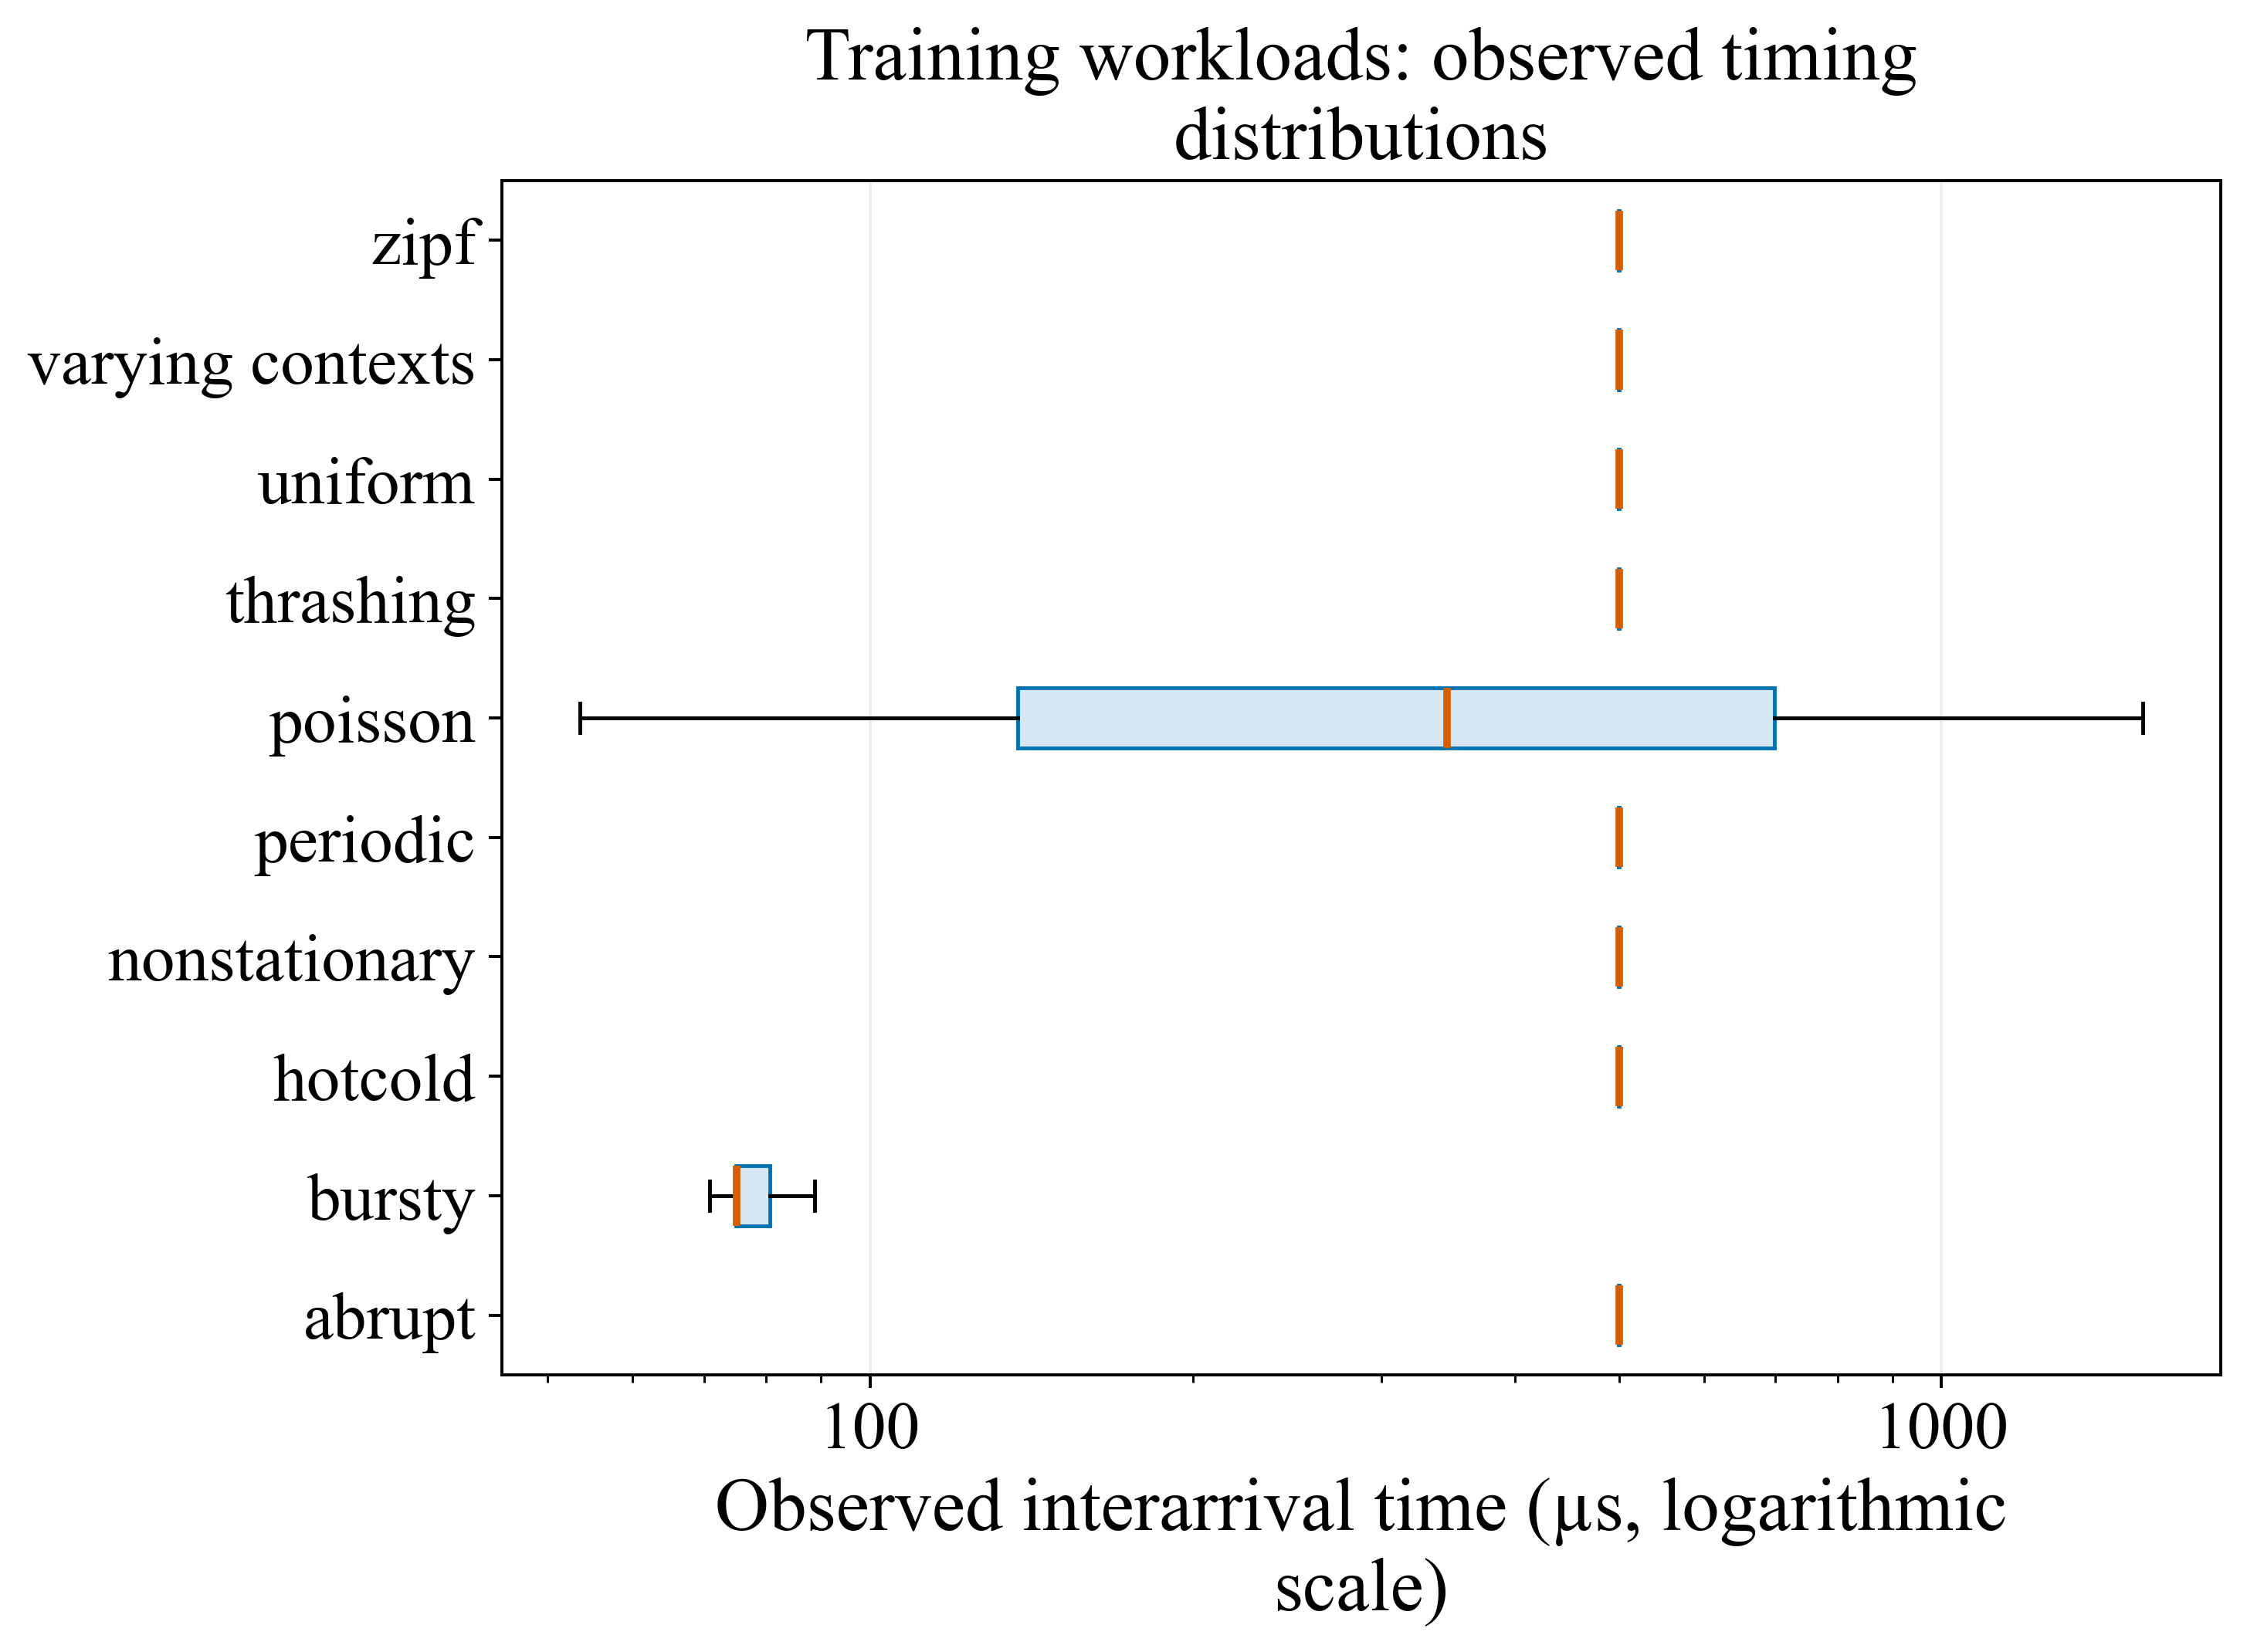

,Observed_contexts,Top8_fraction,Entropy_bits
workload_id,,,
abrupt,55.0,0.505,4.468
bursty,28.0,0.367,4.730
hotcold,50.5,0.912,3.627
nonstationary,64.0,0.176,5.956
periodic,59.0,0.855,3.497
poisson,64.0,0.178,5.952
thrashing,17.0,0.472,4.087
uniform,64.0,0.177,5.955
varying_contexts,122.5,0.327,6.264


In [6]:
families=sorted(df.workload_id.unique())
fig,ax=plt.subplots(figsize=(8.2,6.0))
values=[df.loc[df.workload_id.eq(w),"interarrival_us"].to_numpy() for w in families]
ax.boxplot(values,orientation="horizontal",tick_labels=[w.replace("_"," ") for w in families],showfliers=False,patch_artist=True,
    boxprops={"facecolor":"#D5E8F4","edgecolor":COLORS[0]},medianprops={"color":COLORS[1],"linewidth":2})
from matplotlib.ticker import FuncFormatter, NullFormatter
ax.set_xscale("log");ax.xaxis.set_major_formatter(FuncFormatter(lambda value,position:f"{value:g}"));ax.xaxis.set_minor_formatter(NullFormatter());ax.set_xlabel("Observed interarrival time (µs, logarithmic scale)")
ax.set_title("Training workloads: observed timing distributions")
ax.grid(axis="x",alpha=.2);fig.tight_layout()
source=df.groupby("workload_id").interarrival_us.quantile([.25,.5,.75,.95,.99]).rename("interarrival_us").reset_index()
save_figure(fig,"interarrival_distributions",source)
counts=df.groupby(["workload_id","session_id","key_id"]).size().rename("requests").reset_index()
concentration=[]
for (w,s),g in counts.groupby(["workload_id","session_id"]):
    p=g.requests/g.requests.sum(); concentration.append({"workload_id":w,"session_id":s,"observed_contexts":len(g),"top8_fraction":g.requests.nlargest(8).sum()/g.requests.sum(),"entropy_bits":-(p*np.log2(p)).sum()})
concentration=pd.DataFrame(concentration)
save_table(concentration.groupby("workload_id").agg(Observed_contexts=("observed_contexts","median"), Top8_fraction=("top8_fraction","mean"), Entropy_bits=("entropy_bits","mean")).round(3),"key_concentration")

**Figure note and interpretation.** Blue boxes span the interquartile range, orange lines are medians, and black whiskers extend to the most extreme observations within 1.5 IQR. Outlying points are omitted from this figure only; all observations and p95/p99 remain in the source tables. Long idle intervals in the burst workload therefore must not be inferred absent. Top-eight contexts account for 91.2% of hot/cold requests versus 17.7% for uniform requests. Global concentration alone misses changing popular contexts.

## 01.7–01.9 · Temporal dependence and preliminary reuse structure

Future intervals are used **only as descriptive outcomes**, never as input features. Sessions are processed separately. The last horizon of each session is right-censored and excluded. Event times describe server processing; scheduled arrivals also remain available for later policy-independent workload replay. No model is fitted here.

horizon_ms,5,20
workload_id,,
abrupt,0.622,0.900
bursty,0.861,0.966
hotcold,0.622,0.910
nonstationary,0.477,0.704
periodic,0.753,0.847
poisson,0.145,0.468
thrashing,0.000,1.000
uniform,0.145,0.462
varying_contexts,0.270,0.551


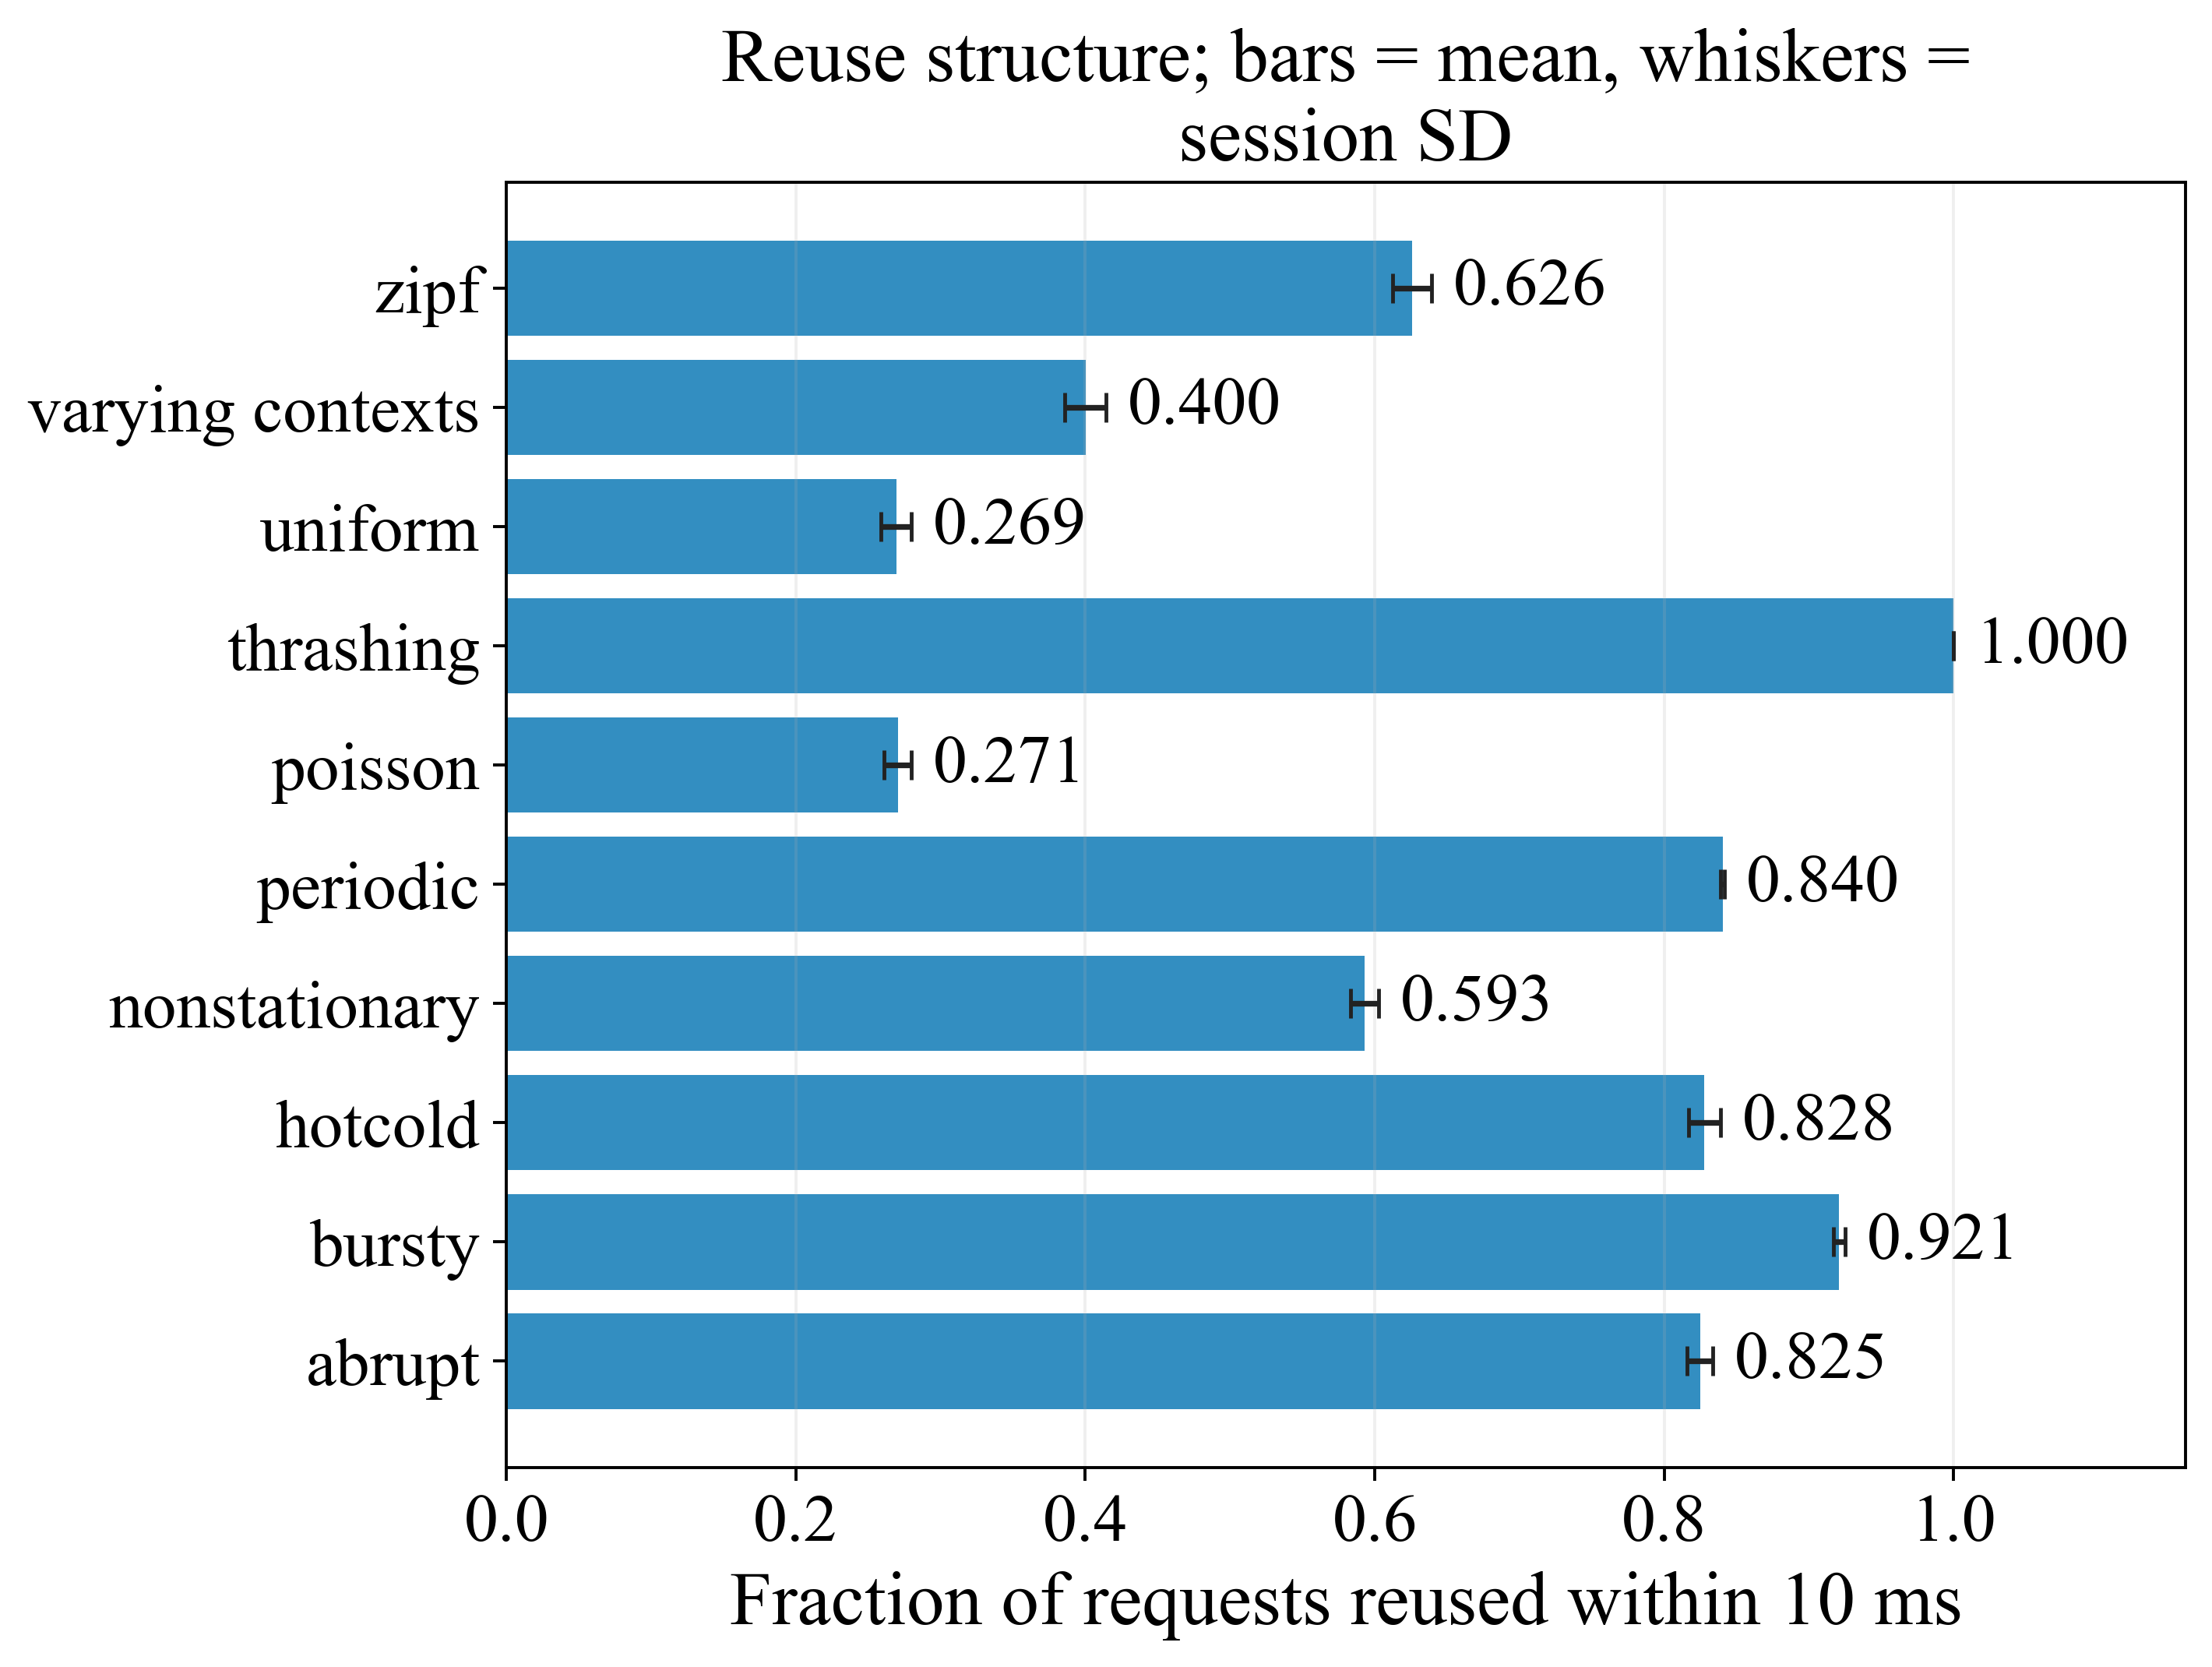

,iat_lag1_correlation,immediate_repeat_fraction,half_session_total_variation
workload_id,,,
abrupt,-0.434,0.102,0.945
bursty,0.924,0.249,0.918
hotcold,-0.445,0.100,0.113
nonstationary,-0.452,0.118,0.609
periodic,-0.368,0.002,0.077
poisson,-0.009,0.015,0.188
thrashing,-0.391,0.000,0.014
uniform,-0.401,0.014,0.195
varying_contexts,-0.492,0.044,0.628


In [7]:
eda=df.sort_values(["session_id","sequence_index"]).copy()
eda["next_same_key_ns"]=eda.groupby(["session_id","key_id"]).timestamp_ns.shift(-1)-eda.timestamp_ns
ends=eda.groupby("session_id").timestamp_ns.transform("max")
reuse_rows=[]
for horizon in design["candidate_prediction_horizons_ms"]:
    valid=eda.timestamp_ns.le(ends-horizon*1e6)
    part=eda.loc[valid].copy();part["reuse"] = part.next_same_key_ns.le(horizon*1e6)
    for (w,s),g in part.groupby(["workload_id","session_id"]):
        reuse_rows.append({"workload_id":w,"session_id":s,"horizon_ms":horizon,"n":len(g),"reuse_fraction":g.reuse.mean()})
reuse=pd.DataFrame(reuse_rows)
reuse_summary=reuse.groupby(["workload_id","horizon_ms"]).agg(Sessions=("session_id","size"), Eligible_events=("n","sum"), Reuse_fraction=("reuse_fraction","mean")).reset_index()
save_table(reuse_summary.pivot(index="workload_id",columns="horizon_ms",values="Reuse_fraction").round(3),"reuse_horizons", exclude=[10])
fig,ax=plt.subplots(figsize=(8.0,6.0))
selected=reuse[reuse.horizon_ms.eq(10)].groupby("workload_id").reuse_fraction.agg(["mean","std"]).reindex(families)
ax.barh([w.replace("_"," ") for w in families],selected["mean"],color=COLORS[0],alpha=.8)
ax.errorbar(selected["mean"],np.arange(len(families)),xerr=selected["std"],fmt="none",ecolor="#222222",capsize=4)
for i,(mean,sd) in enumerate(zip(selected["mean"],selected["std"])):
    ax.text(mean+sd+.015,i,f"{mean:.3f}",va="center",fontsize=18)
ax.set_xlim(0,1.16);ax.set_xticks(np.arange(0,1.01,.2));ax.set_xlabel("Fraction of requests reused within 10 ms")
ax.set_title("Reuse structure; bars = mean, whiskers = session SD")
ax.grid(axis="x",alpha=.2);fig.tight_layout()
save_figure(fig,"reuse_by_workload",reuse[reuse.horizon_ms.eq(10)])
dependence=[]
for (w,s),g in eda.groupby(["workload_id","session_id"]):
    intervals=g.interarrival_us.to_numpy(); repeats=g.key_id.eq(g.key_id.shift()).astype(float)
    first=g.iloc[:len(g)//2].key_id.value_counts(normalize=True);second=g.iloc[len(g)//2:].key_id.value_counts(normalize=True)
    ids=first.index.union(second.index)
    dependence.append({"workload_id":w,"session_id":s,"iat_lag1_correlation":pd.Series(intervals).autocorr(1),"immediate_repeat_fraction":repeats.iloc[1:].mean(),"half_session_total_variation":.5*(first.reindex(ids,fill_value=0)-second.reindex(ids,fill_value=0)).abs().sum()})
dependence=pd.DataFrame(dependence)
save_table(dependence.groupby("workload_id").mean(numeric_only=True).round(3),"temporal_dependence")

**Interpretation.** At a 10 ms descriptive horizon, reuse ranges from 26.9% (uniform) to 92.1% (bursty), with the cyclic thrashing workload at 100%. High reuse does not ensure a hit in a 16-entry cache when the cycle contains 17 keys. Negative lag-one correlations in nearly fixed-rate interarrival times mainly reflect scheduling jitter around a fixed schedule; they are not evidence of production predictability. The abrupt workload has a large half-session distribution shift (total variation 0.945), motivating shift diagnostics.

## Feasibility pilot: separate observation unit

The pilot has three fresh processes per backend, each with 100 untimed warm-up iterations and 2,000 measured repeated-input iterations. Portable, arithmetic-only, SHA3-only and fully optimized builds use the same pinned library revision. Each process also checks interoperability with OpenSSL and implicit rejection of a modified ciphertext.

OpenSSL's reconstruction number includes key-generation context setup and object destruction, whereas its decapsulation reuses a context. This is an API reference, not an arithmetic-only head-to-head comparison. The pilot arena is locked, but OpenSSL's internal allocations are not claimed to be audited or fully locked. The current instrument does not measure standalone Encaps or OS entropy cost; those remain required in Notebook 03.

Zeroization (µs)     
                       mean  std
backend                         
arith_only            0.074  0.0
optimized             0.074  0.0
portable              0.074  0.0
sha3_only             0.074  0.0

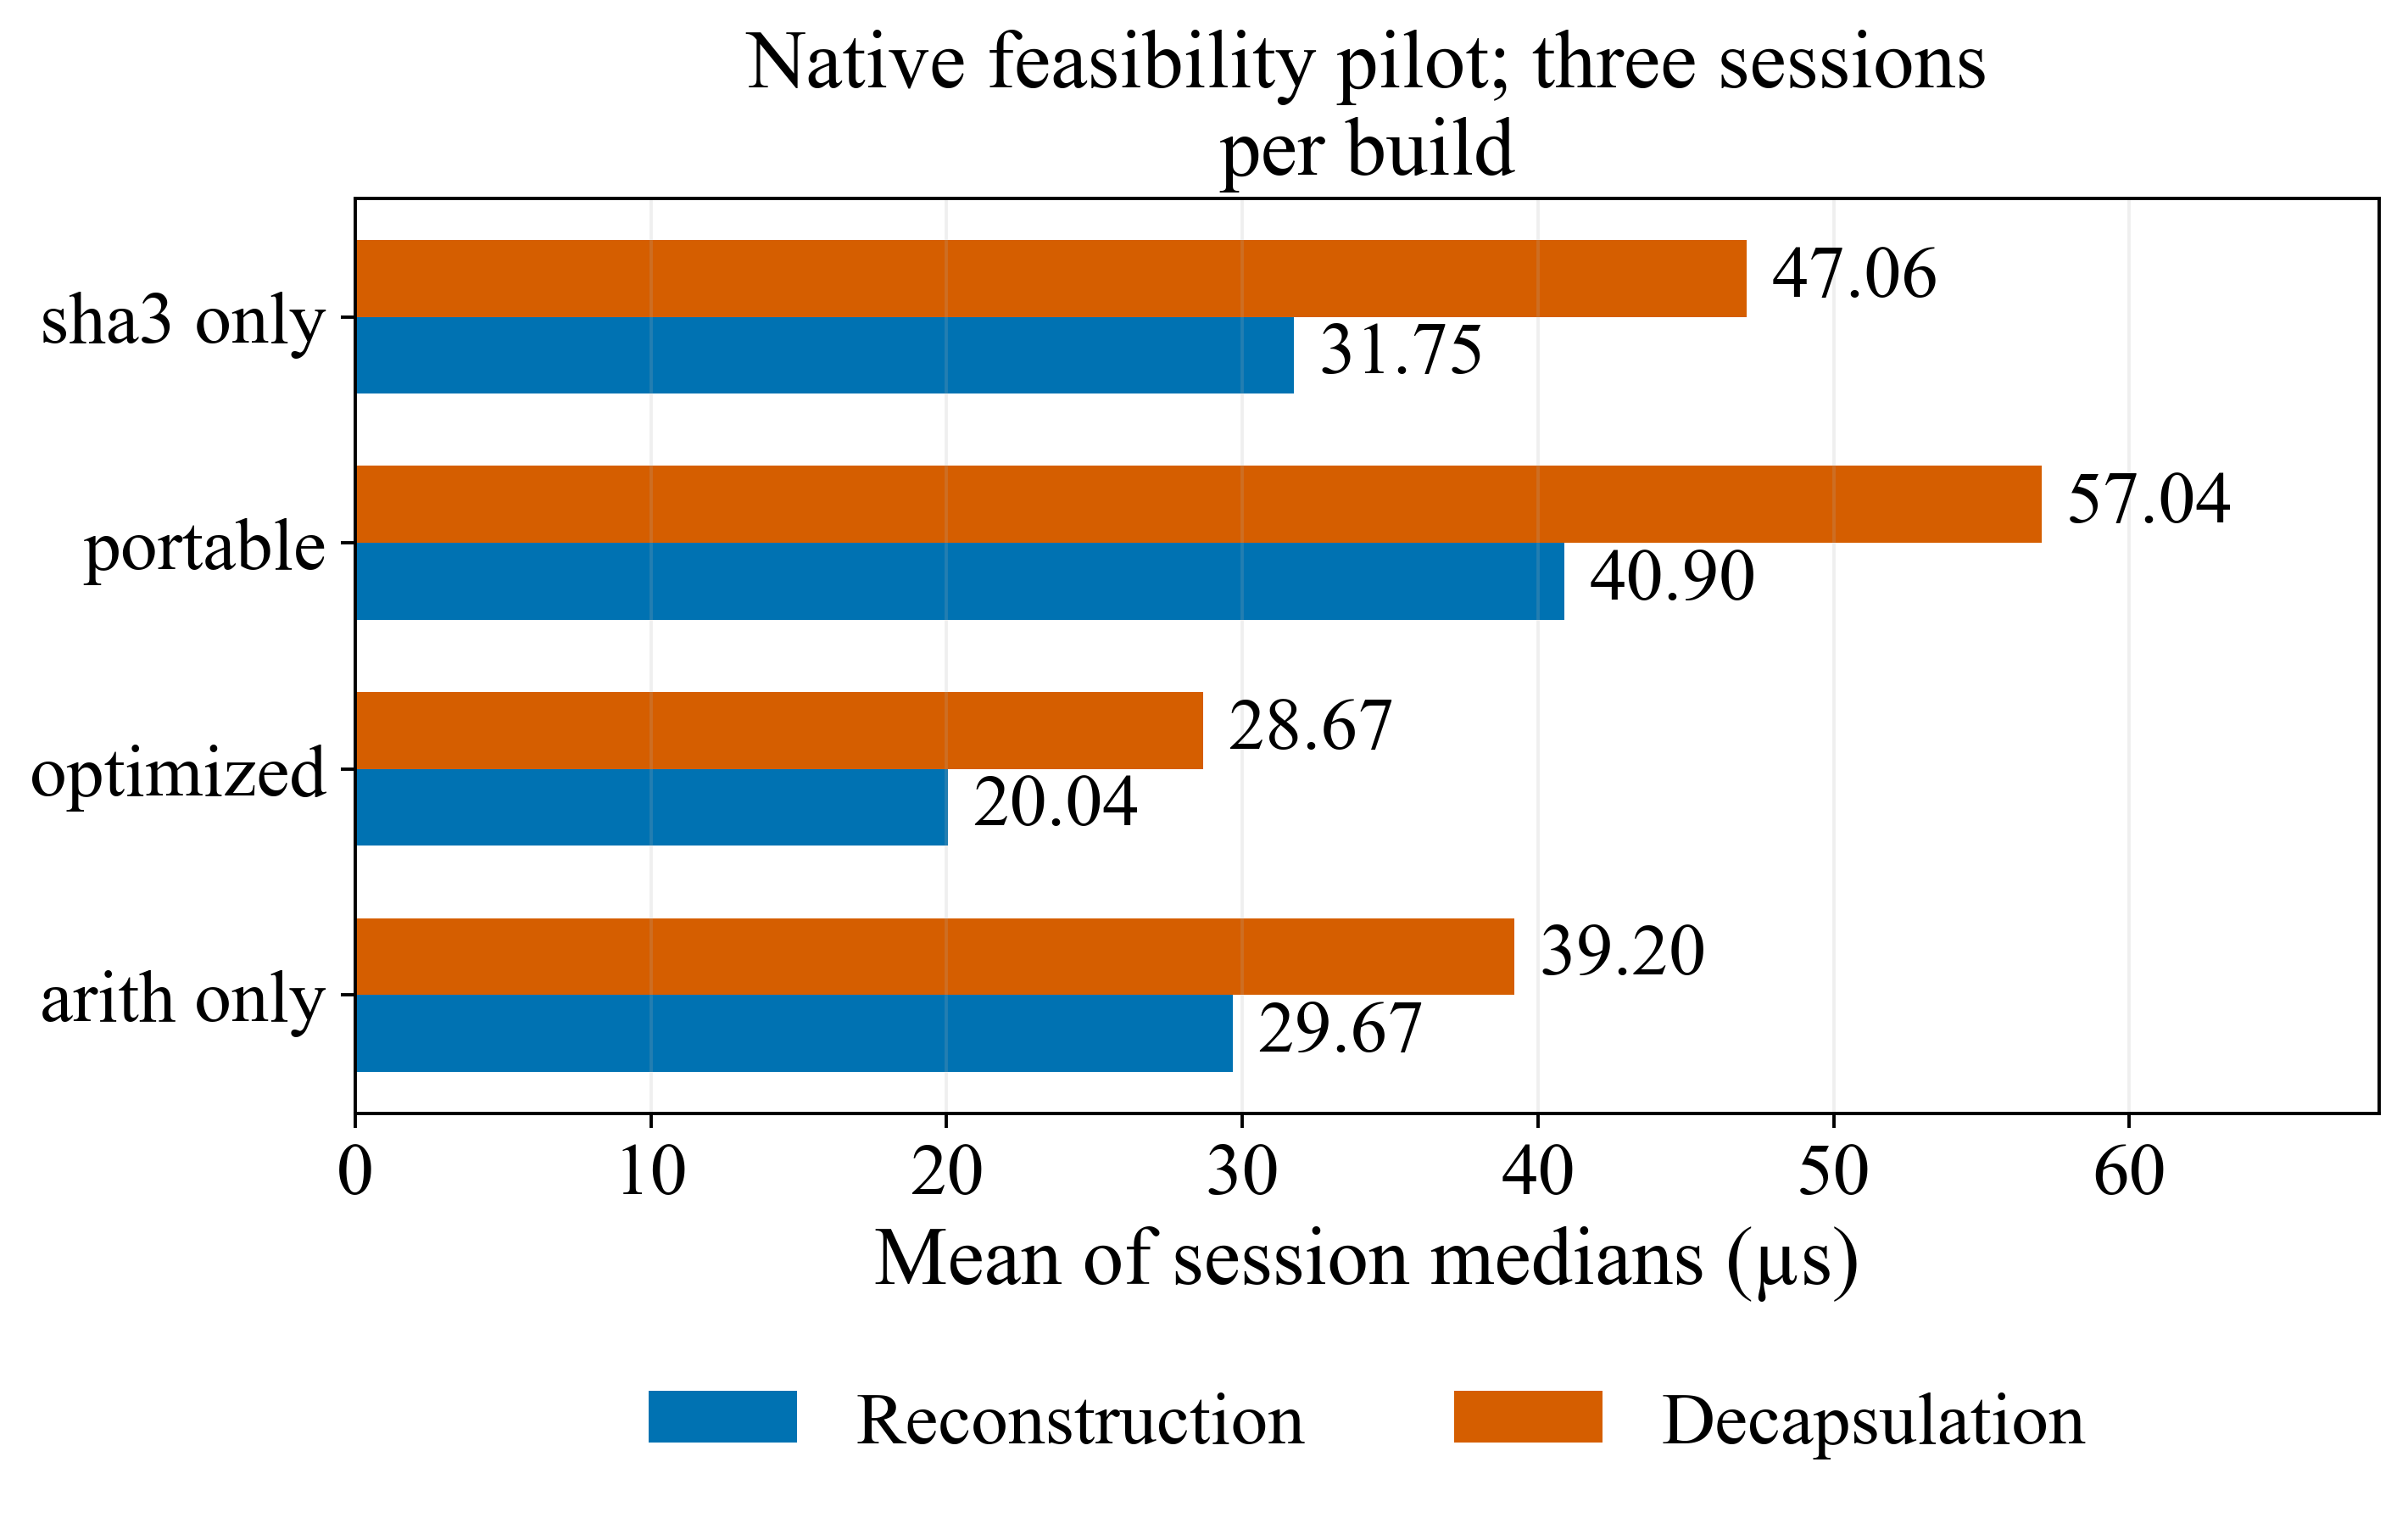

In [8]:
pilot=pd.concat([pd.read_csv(p) for p in sorted((RAW/"Pilot_20261018").glob("*.csv"))],ignore_index=True)
assert len(pilot)==3*4*2000
pcols=[c for c in pilot if c.endswith("_ns")]
ps=pilot.groupby(["backend","session"])[pcols].median()/1000
pilot_summary=ps.groupby("backend").agg(["mean","std"])
save_table(pilot_summary[["reconstruct_ns","decaps_ns","zeroize_2400_ns"]].rename(columns={"reconstruct_ns":"Reconstruction (µs)","decaps_ns":"Decapsulation (µs)","zeroize_2400_ns":"Zeroization (µs)"}).round(3),"pilot_session_medians_us", columns=['Zeroization (µs)'])
fig,ax=plt.subplots(figsize=(8.0,5.0))
summary=ps.groupby("backend")[["reconstruct_ns","decaps_ns"]].mean()
y=np.arange(len(summary));h=.34
bars_rec=ax.barh(y-h/2,summary.reconstruct_ns,h,label="Reconstruction",color=COLORS[0])
ax.bar_label(bars_rec,fmt="%.2f",padding=6,fontsize=18)
bars_dec=ax.barh(y+h/2,summary.decaps_ns,h,label="Decapsulation",color=COLORS[1])
ax.bar_label(bars_dec,fmt="%.2f",padding=6,fontsize=18)
ax.set_xlim(0,summary.to_numpy().max()*1.20)
ax.set_yticks(y,[s.replace("_"," ") for s in summary.index]);ax.set_xlabel("Mean of session medians (µs)")
ax.set_title("Native feasibility pilot; three sessions per build")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.23),ncol=2,frameon=False);ax.grid(axis="x",alpha=.2)
fig.subplots_adjust(left=.22,bottom=.3,top=.88)
save_figure(fig,"pilot_costs",ps.rename(columns=lambda x:x.replace("_ns","_us")).reset_index())
opt=ps.loc["optimized"]
rec=float(opt.reconstruct_ns.mean());dec=float(opt.decaps_ns.mean())

**Interpretation.** The optimized backend has a gross reconstruction-saving opportunity of about 20 µs per avoided reconstruction. Copying/clearing a 2,400-byte buffer is much cheaper in this pilot; model and policy overhead still need direct measurement. Backend acceleration is attributed to mlkem-native. Three short repeated-input runs do not establish sustained system superiority.

## IoT-23 as external context

IoT-23 capture timing comes from the `ts` connection field, not Zeek's processing `#open`/`#close` headers. Logs can be unsorted. Scenario and device context can reveal source identity; traffic-derived samples must therefore be grouped by capture/device. No traffic-to-key mapping is introduced here. Original licensing notices conflict with the catalog's broad license description; redistribution permission is unresolved.

In [9]:
iot_logs=sorted((DATA/"raw/IoT23").rglob("conn.log.labeled"))
if not iot_logs:
    print("IoT-23 connection logs are not redistributed with this repository; see dataset/README.md to download them.")
else:
    iot_rows=[]
    for p in sorted((DATA/"raw/IoT23").rglob("conn.log.labeled")):
        times=[]; labels={}; bad=0
        with p.open() as f:
            for line in f:
                if line.startswith("#") or not line.strip(): continue
                fields=line.split()
                try: times.append(float(fields[0]))
                except (ValueError,IndexError): bad+=1;continue
                lab=fields[-2] if len(fields)>2 else "unknown"
                labels[lab]=labels.get(lab,0)+1
        arr=np.asarray(times)
        iot_rows.append({"Capture":p.relative_to(DATA/"raw/IoT23").parts[0],"Connections":len(arr),"Duration_h":(arr.max()-arr.min())/3600,"Out_of_order":int((np.diff(arr)<0).sum()),"Bad_timestamp":bad,"Labels":", ".join(f"{k}: {v}" for k,v in sorted(labels.items()))})
    iot=pd.DataFrame(iot_rows).set_index("Capture")
    save_table(iot.round(3),"iot23_context")
    assert iot.Bad_timestamp.eq(0).all()
    assert iot.Connections.gt(0).all()


,Connections,Duration_h,Out_of_order,Bad_timestamp,Labels
Capture,,,,,
CTU-Honeypot-Capture-4-1,452,21.863,128,0,benign: 452
CTU-Honeypot-Capture-5-1,1374,5.486,414,0,benign: 1374
CTU-Honeypot-Capture-7-1,130,1.383,45,0,benign: 130
CTU-IoT-Malware-Capture-20-1,3209,23.983,313,0,"Benign: 3193, Malicious: 16"
CTU-IoT-Malware-Capture-3-1,156103,36.124,8252,0,"Benign: 4536, Malicious: 151567"
CTU-IoT-Malware-Capture-34-1,23145,23.999,1886,0,"Benign: 1923, Malicious: 21222"
CTU-IoT-Malware-Capture-42-1,4426,8.347,1315,0,"Benign: 4420, Malicious: 6"
CTU-IoT-Malware-Capture-8-1,10403,23.999,1856,0,"Benign: 2181, Malicious: 8222"


**Interpretation.** All eight IoT-23 logs have parseable connection timestamps, but every log contains records out of timestamp order. Sort only in derived data if used later. Malicious-labelled captures can contain predominantly benign connections (20-1 and 42-1); neither the capture name nor a random row split is an adequate supervised protocol. These sources are contextual and do not supply ML-KEM reuse labels.

## 01.10 · Evaluation contract and information boundary

Features may include request counts, time since previous use, interarrival statistics and causal workload-change indicators. They may not include future reuse, future cache state, generator family, a global rank computed from an entire session, secret bytes or session/key identity. Key IDs are permuted per session; identical numeric IDs across sessions do not denote the same key.

The split unit is the session, with distinct workload RNG seeds. The future test is separated by generation namespace and acquisition time. Within training, forward blocked folds must purge the maximum 50 ms history plus a maximum 20 ms label horizon (70 ms). Preprocessing is fitted inside each training fold. The development sessions support selection; final test supports the frozen comparison only. Runtime adaptation may use previous unlabeled test requests, as an online deployment would, but cannot train on their unavailable future labels.

A 1,000-request session gives limited drift cycles and tail precision. Session-level replication controls event pseudo-replication but not hardware external validity. A workload family is a designed stratum, not a new independent board.

In [10]:
split_table=manifest.copy()
split_table["collection"]="development_v1"
split_table["measurement_host"]="Raspberry Pi 5"
split_table.to_csv(DATA/"splits/development_session_assignments.csv",index=False)
assert set(split_table.loc[split_table.split.eq("train"),"workload_seed"]).isdisjoint(split_table.loc[split_table.split.eq("development"),"workload_seed"])
all_events.to_parquet(DATA/"interim/development_events.parquet",index=False)
checksums={acquisition_path(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in [DATA/"splits/development_session_assignments.csv",DATA/"interim/development_events.parquet",ROOT/"support/configs/development_design.json"]}
(ROOT/"support/manifests/NotebookRuns/01_derived_hashes.json").write_text(json.dumps(checksums,indent=2)+"\n")
adequacy=pd.DataFrame([
    ("Training replication",f"{manifest.split.eq('train').sum()} independent process sessions", "Same physical board; controlled schedules"),
    ("Development replication",f"{manifest.split.eq('development').sum()} sessions", "Selection only; not final confirmation"),
    ("Final evaluation", "60 reserved sessions; no outcomes accessed", "Generate only after pipeline freeze"),
    ("Workload diversity",f"{manifest.workload_id.nunique()} designed families", "Not a production population sample"),
    ("Cryptographic operations",f"{len(all_events):,} successful measured decapsulations", "Initial workload policy is seed-only"),
    ("Energy", "Unavailable", "External power instrument absent"),
    ("Hardware generalization", "One Raspberry Pi 5", "No between-device uncertainty")],columns=["Dimension","Evidence","Limitation"]).set_index("Dimension")
save_table(adequacy,"adequacy")

,Evidence,Limitation
Dimension,,
Training replication,60 independent process sessions,Same physical board; controlled schedules
Development replication,30 sessions,Selection only; not final confirmation
Final evaluation,60 reserved sessions; no outcomes accessed,Generate only after pipeline freeze
Workload diversity,10 designed families,Not a production population sample
Cryptographic operations,"90,000 successful measured decapsulations",Initial workload policy is seed-only
Energy,Unavailable,External power instrument absent
Hardware generalization,One Raspberry Pi 5,No between-device uncertainty


## Additional temporal diagnostics

A recurrence profile tests equality of context identities at different request lags; it never treats numeric key IDs as continuous values. The rate profile uses scheduled arrivals, preserving the exogenous workload definition separately from server scheduling jitter. These are descriptive training-only diagnostics.

The rate profile contains every complete 10 ms window within each session's observed schedule, including zero-request windows. Windows are left-closed and right-open; an event exactly on a boundary belongs to the next window. The final incomplete window is excluded. At each elapsed time, the plotted mean uses only sessions with a complete window there; no unobserved time beyond a session's last scheduled event is filled with zeros. Integer nanosecond boundaries avoid floating-point bin assignment drift.

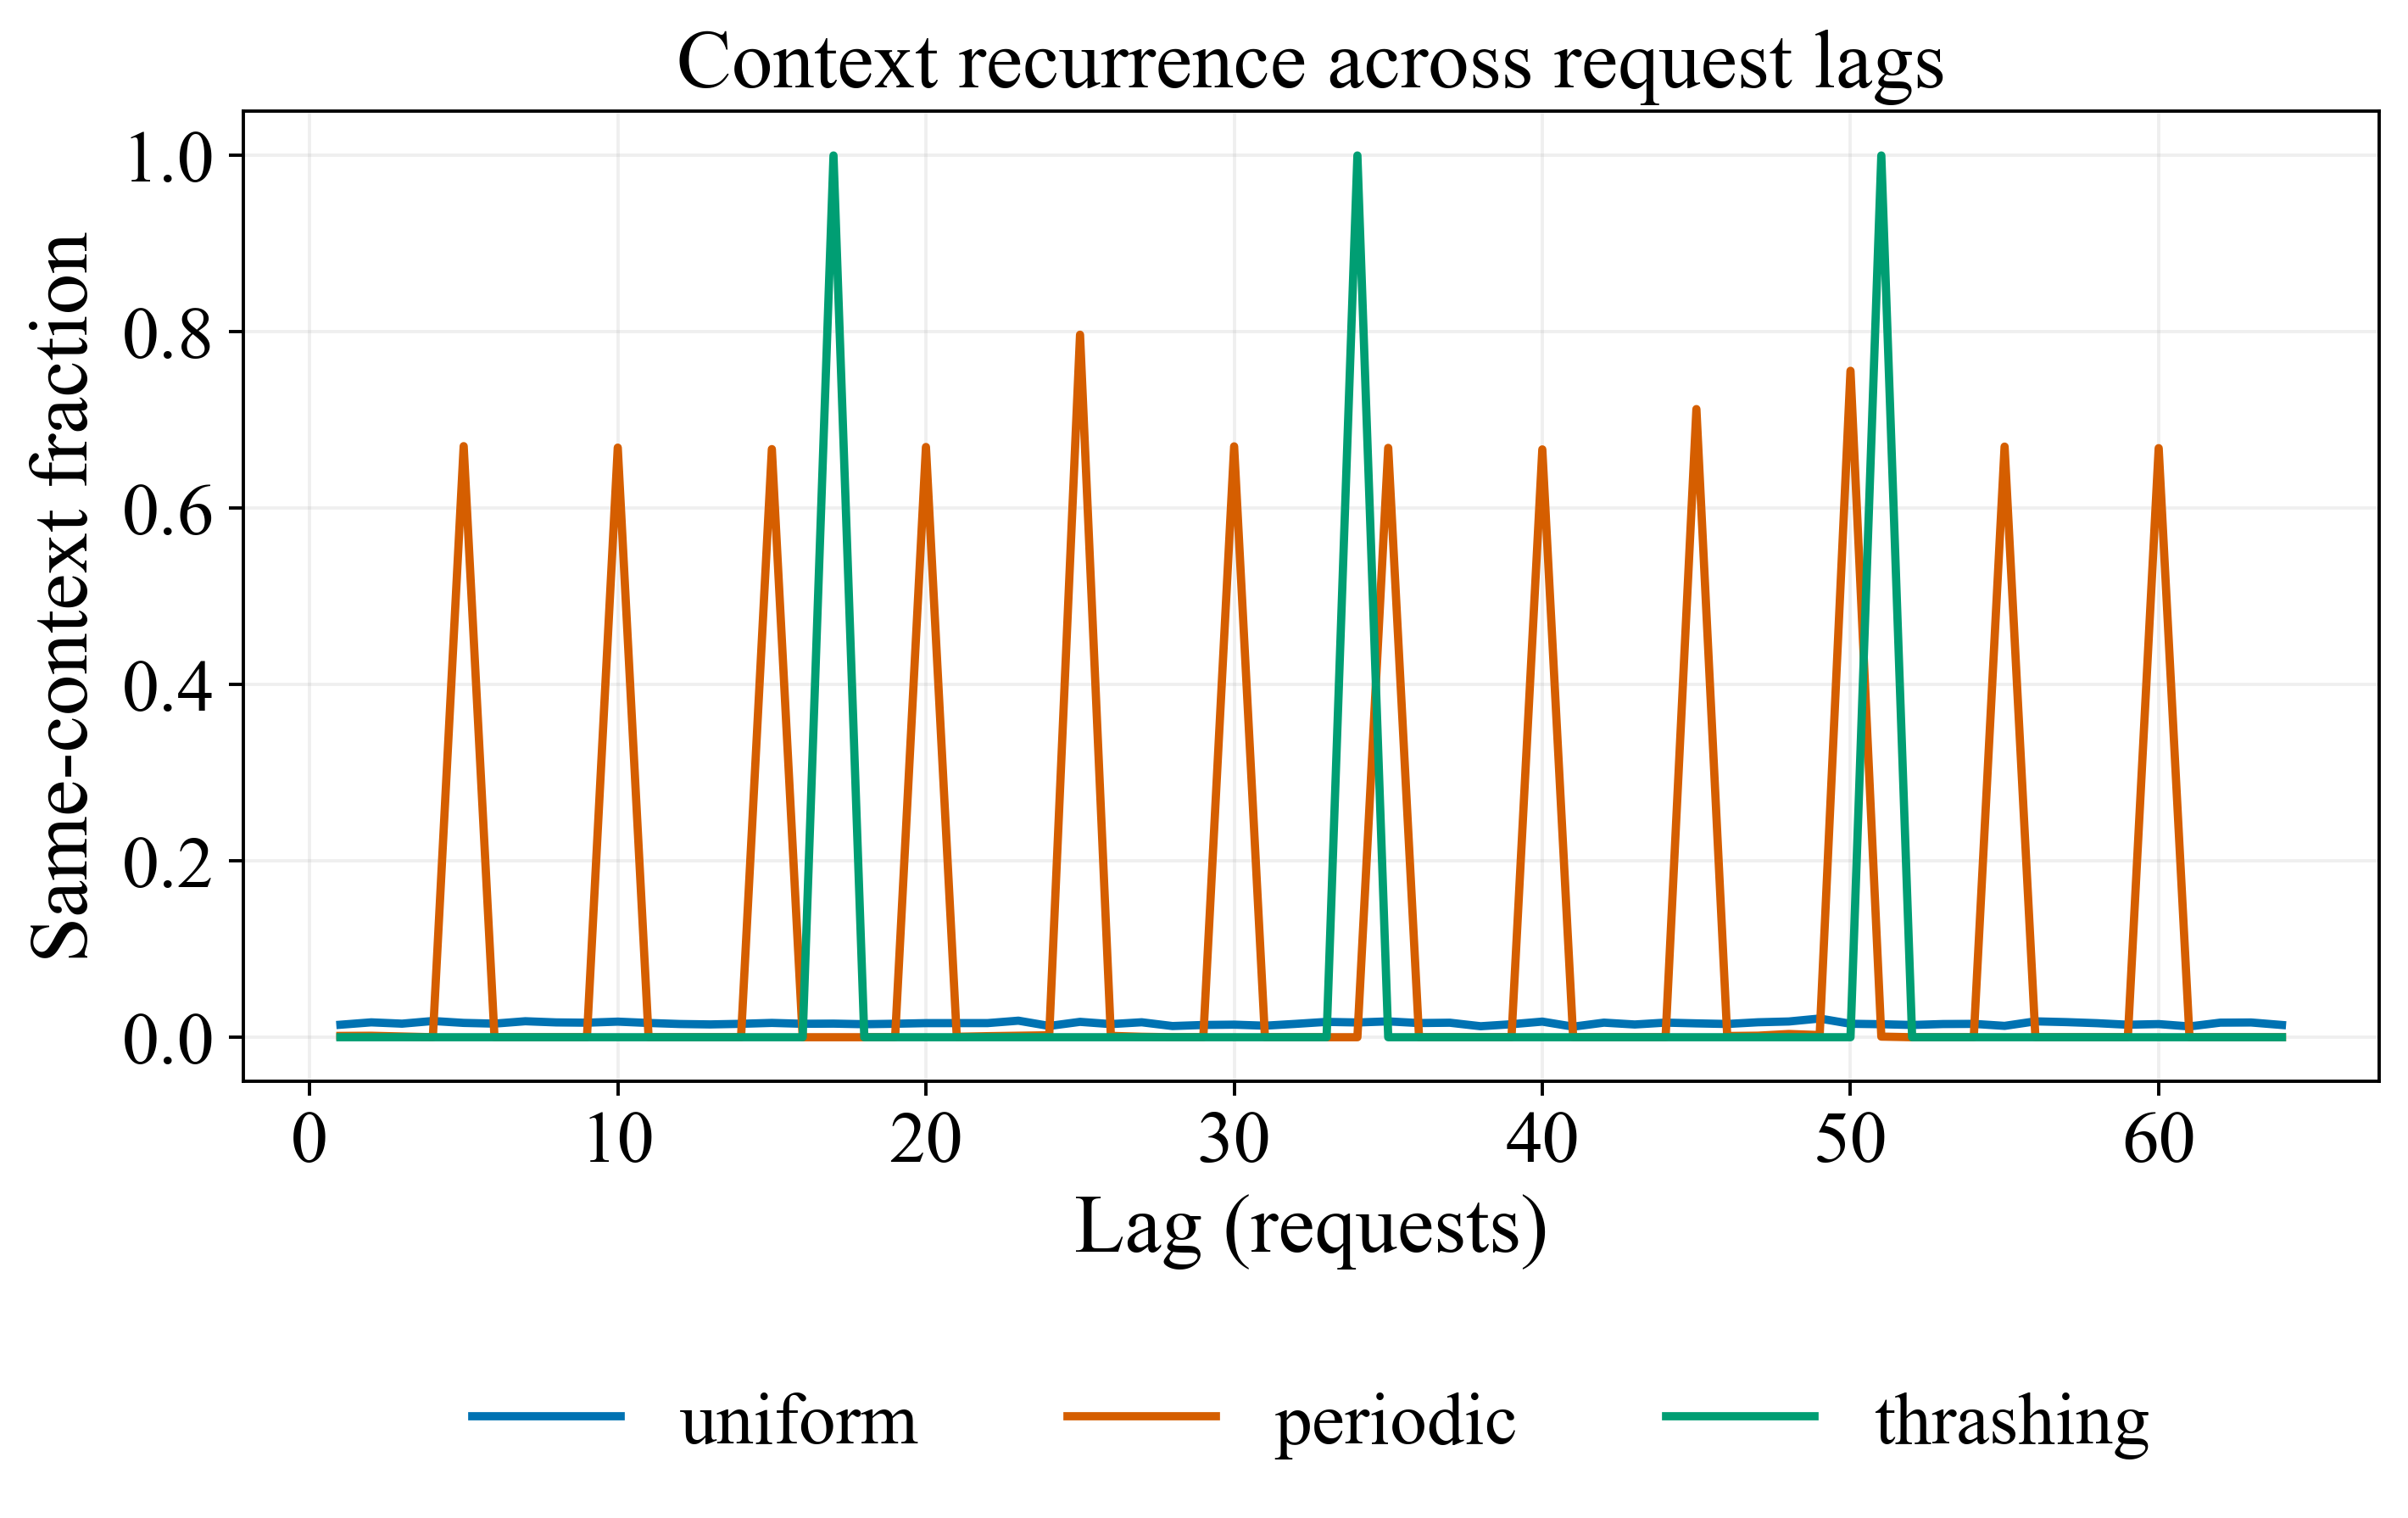

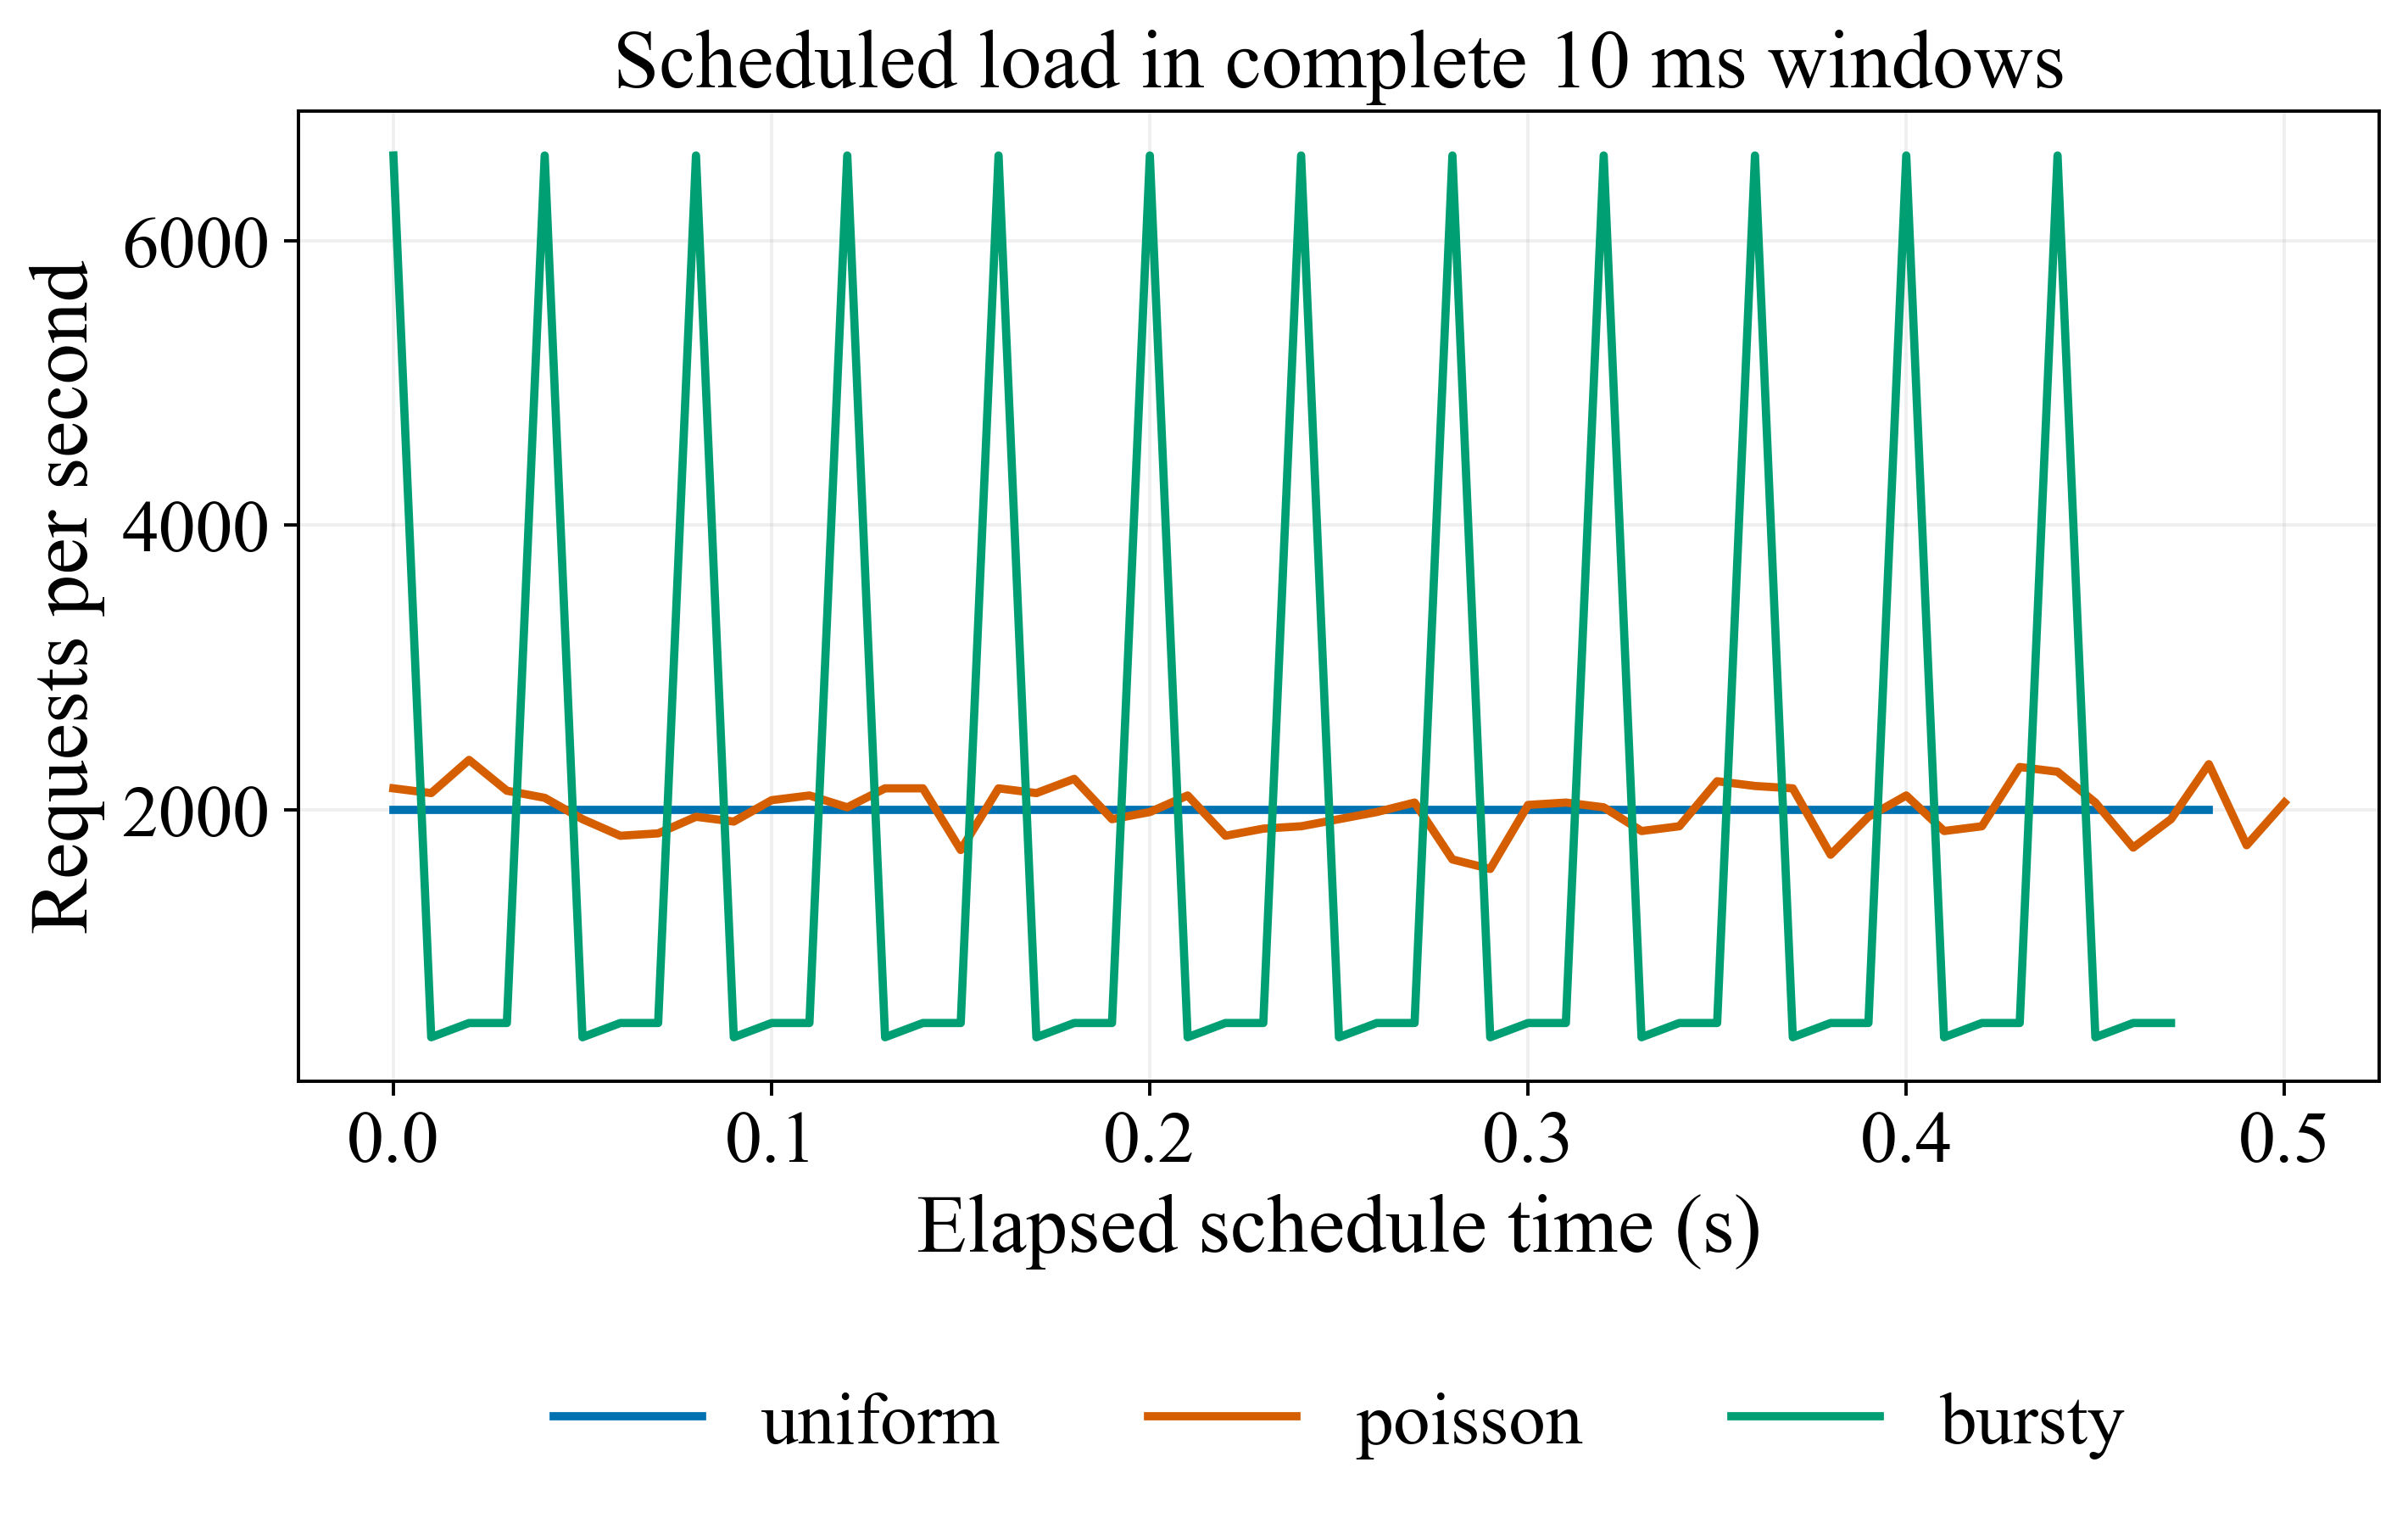

,Median_peak_lag,Mean_peak_recurrence
workload_id,,
abrupt,17.0,0.124
bursty,4.0,0.272
hotcold,49.0,0.129
nonstationary,2.0,0.130
periodic,25.0,0.797
poisson,31.0,0.025
thrashing,17.0,1.000
uniform,49.0,0.027
varying_contexts,21.0,0.055


In [11]:
recurrence_rows=[]
for (w,s),g in df.groupby(["workload_id","session_id"]):
    keys=g.sort_values("sequence_index").key_id.to_numpy()
    for lag in range(1,65):
        recurrence_rows.append({"workload_id":w,"session_id":s,"lag":lag,"same_context_fraction":np.mean(keys[lag:]==keys[:-lag])})
recurrence=pd.DataFrame(recurrence_rows)
fig,ax=plt.subplots(figsize=(8.0,5.0))
for color,workload in zip(COLORS,["uniform","periodic","thrashing"]):
    r=recurrence[recurrence.workload_id.eq(workload)].groupby("lag").same_context_fraction.mean()
    ax.plot(r.index,r.values,label=workload,color=color,linewidth=2)
ax.set_xlabel("Lag (requests)");ax.set_ylabel("Same-context fraction")
ax.set_title("Context recurrence across request lags")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.25),ncol=3,frameon=False)
ax.grid(alpha=.2);fig.subplots_adjust(bottom=.32,left=.13,top=.88)
save_figure(fig,"context_recurrence",recurrence)
WINDOW_NS=10_000_000

def complete_window_counts(relative_ns, window_ns=WINDOW_NS):
    relative_ns=np.asarray(relative_ns,dtype=np.int64)
    assert relative_ns.ndim==1 and len(relative_ns)>0
    assert relative_ns[0]==0 and np.all(np.diff(relative_ns)>=0)
    assert window_ns>0
    n_complete=int(relative_ns[-1]//window_ns)
    if n_complete==0:
        return np.zeros(0,dtype=np.int64)
    observed=relative_ns[relative_ns<n_complete*window_ns]
    counts=np.bincount(observed//window_ns,minlength=n_complete)
    assert len(counts)==n_complete and counts.sum()==len(observed)
    return counts

# Hand-specified checks of empty windows, exact boundaries and a partial tail.
assert np.array_equal(complete_window_counts([0,10_000_000,30_000_000]),[1,1,0])
assert np.array_equal(complete_window_counts([0,9_999_999,10_000_000,20_000_000,35_000_000]),[2,1,1])
assert len(complete_window_counts([0,9_999_999]))==0
rate_rows=[]
for (w,s),g in df.groupby(["workload_id","session_id"]):
    g=g.sort_values("sequence_index")
    arrival_ns=g.scheduled_arrival_ns.to_numpy(dtype=np.int64)
    relative_ns=arrival_ns-arrival_ns[0]
    counts=complete_window_counts(relative_ns)
    for b,count in enumerate(counts):
        rate_rows.append({"workload_id":w,"session_id":s,"time_s":b*WINDOW_NS/1e9,"rate_per_s":count*1e9/WINDOW_NS})
rates=pd.DataFrame(rate_rows)
fig,ax=plt.subplots(figsize=(8.0,5.0))
for color,workload in zip(COLORS,["uniform","poisson","bursty"]):
    r=rates[rates.workload_id.eq(workload)].groupby("time_s").rate_per_s.mean()
    ax.plot(r.index,r.values,label=workload,color=color,linewidth=2)
ax.set_xlabel("Elapsed schedule time (s)");ax.set_ylabel("Requests per second")
ax.set_title("Scheduled load in complete 10 ms windows")
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.25),ncol=3,frameon=False)
ax.grid(alpha=.2);fig.subplots_adjust(bottom=.32,left=.15,top=.88)
save_figure(fig,"scheduled_rate",rates)
peaks=recurrence.loc[recurrence.groupby(["workload_id","session_id"]).same_context_fraction.idxmax()]
save_table(peaks.groupby("workload_id").agg(Median_peak_lag=("lag","median"),Mean_peak_recurrence=("same_context_fraction","mean")).round(3),"recurrence_peaks")

## Conclusions

All 90,000 measured decapsulations passed; 60 training and 30 development sessions cover ten controlled workload families. All 55 external source checksums and 271 development-collection checksums match. The eight IoT-23 logs are network-traffic context, not cryptographic key-access ground truth. Their row order is not chronological; any later temporal use must sort within each capture.

There is a measurable reconstruction cost (optimized pilot median of session medians: 20.043 µs) and substantial reuse heterogeneity. A 17-context cyclic workload has perfect 10 ms reuse but can defeat a 16-entry recency cache. Periodic/recurrence peaks describe the designed generator; maxima in random workloads are not evidence of statistically significant periodicity. No proposed-policy benefit has yet been measured.

Frequency varied between 1.6 and 2.4 GHz while cycle counts were comparatively stable. The initial half-second sessions therefore establish development data and instrument feasibility, not sustained system performance. Main comparisons require matched CPU conditions, longer runs, complete management overhead and fresh held-out sessions. Energy, production traffic generalization, between-board uncertainty, side-channel resistance and FIPS module certification are not established.

Notebook 02 will use the exogenous scheduled-arrival clock for labels and bounded historical features, preserving the same session split. This prevents a cache policy's execution speed from redefining its own workload labels. Actual wall-clock latency and secret-residency constraints remain separate native measurements.